# Human detection and tracking: bidirectional phase and attenuation

The same loading as `roomsweeps_processing/variance_processing.ipynb`, up to θ̂ and α̂ of every link.

Data: `human_detection_tracking_data/<exp>/` (CSV and `positions.txt`). The same 8 tags stay in place in every
experiment. `baseline` has no person in the room. In the others, a person stands at the place the folder is named
after (`center`, `northeast`, `northwest`, `southeast`, `southwest`). Floor labels 1–136 are located in 3-D in the
merged room scan `roomscans/merged.ply`, and their centres are in `roomscans/merged_markers.csv` (metres, z up,
floor ≈ 0).

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d

ROOT = Path.cwd().parent   # organized_multitag (data); run from organized_multitag/human_detection_tracking_processing
DATA_DIR = ROOT / "human_detection_data"
SCAN_DIR = ROOT / "roomscans"
MESH_PATH = SCAN_DIR / "merged.ply"
MARKERS_PATH = SCAN_DIR / "merged_markers.csv"

# the experiment every other one is compared against (distance from baseline, plot defaults)
BASELINE = "baseline"

# experiment order: the empty room first, then the person's positions
# EXP_ORDER = ["baseline", "center", "northeast", "northwest", "southeast", "southwest", "baseline2", "baseline3_excitermoved", "baseline4_excitermoved"]
EXP_ORDER = ["baseline", "center", "northeast", "northwest", "southeast", "southwest"]

# one colour per arm of the tag cross: tags 1-4 down column 8, tags 5-8 across row 5
TAG_GROUPS = {"T1–T4 (column 8)": range(1, 5), "T5–T8 (row 5)": range(5, 9)}
GROUP_COLORS = ["#2a78d6", "#eb6834"]

## Floor markers (label → x, y, z in the merged scan)

In [2]:
markers = pd.read_csv(MARKERS_PATH).set_index("index").sort_index()
print(f"{len(markers)} markers, labels {markers.index.min()}–{markers.index.max()}")


def marker_xyz(label):
    # Floor label -> (x, y, z) in metres. `under-N` is one step past N along N's column.
    label = str(label).strip()
    m = re.fullmatch(r"under-(\d+)", label)
    if m:
        n = int(m.group(1))
        p, prev = markers.loc[n, ["x", "y", "z"]], markers.loc[n - 1, ["x", "y", "z"]]
        return tuple(p + (p - prev))
    return tuple(markers.loc[int(label), ["x", "y", "z"]])

136 markers, labels 1–136


## Experiments and tag positions

Every experiment folder needs a positions file. `northwest` has it saved as `positions.txt.txt`, so any file whose
name starts with `positions.txt` is accepted. The tags must be in the same place in every experiment, since only the
person moves, so an experiment with no positions file (e.g. `baseline4_excitermoved`) uses the shared tag positions.

In [3]:
def positions_frame(tags, labels, source):
    df = pd.DataFrame({"tag": [str(t).strip() for t in tags], "label": [str(l).strip() for l in labels]})
    df[["x", "y", "z"]] = np.array([marker_xyz(l) for l in df["label"]])
    df["source"] = source
    return df.set_index("tag")


def positions_path(exp_dir):
    # positions.txt, or a misnamed copy such as positions.txt.txt (None if there is none)
    found = sorted(exp_dir.glob("positions.txt*"))
    assert len(found) <= 1, f"{exp_dir.name}: several positions files {[p.name for p in found]}"
    return found[0] if found else None


def load_positions(exp_dir):
    # positions file -> DataFrame indexed by tag number with label, x, y, z (None if the file is missing)
    path = positions_path(exp_dir)
    if path is None:
        return None
    df = pd.read_csv(path, skipinitialspace=True, dtype=str).dropna()
    return positions_frame(df.iloc[:, 0], df.iloc[:, 1], path.name)


exp_dirs = sorted((d for d in DATA_DIR.iterdir() if d.is_dir()),
                  key=lambda d: (EXP_ORDER.index(d.name) if d.name in EXP_ORDER else len(EXP_ORDER), d.name))
positions = {d.name: load_positions(d) for d in exp_dirs}

inventory = pd.DataFrame({
    "positions file": [positions[d.name]["source"].iloc[0] if positions[d.name] is not None else None
                       for d in exp_dirs],
    "csv": [len(list(d.glob("*.csv"))) for d in exp_dirs],
    "pdfs": [len(list(d.glob("*.pdf"))) for d in exp_dirs],
}, index=[d.name for d in exp_dirs]).rename_axis("exp")
print(inventory.to_string())

# the tags do not move between experiments
loaded = {name: pos for name, pos in positions.items() if pos is not None}
ref_name, ref = next(iter(loaded.items()))
for name, pos in loaded.items():
    assert pos["label"].sort_index().equals(ref["label"].sort_index()), f"{name}: tags moved relative to {ref_name}"
print("\ntag positions (same in every experiment): " + ", ".join(f"T{t}@{l}" for t, l in ref["label"].items()))

# experiments without a positions file: the tags did not move, so use the shared positions
for name, pos in positions.items():
    if pos is None:
        positions[name] = ref.assign(source=f"(from {ref_name})")
        print(f"{name}: no positions file, using the tag positions of {ref_name}")

                           positions file  csv  pdfs
exp                                                 
baseline                    positions.txt    1     3
center                      positions.txt    1     3
northeast                   positions.txt    1     3
northwest               positions.txt.txt    1     3
southeast                   positions.txt    1     3
southwest                   positions.txt    1     3
baseline2                   positions.txt    1     3
baseline3_excitermoved      positions.txt    1     3
baseline4_excitermoved      positions.txt    1     3

tag positions (same in every experiment): T1@68, T2@69, T3@71, T4@72, T5@62, T6@78, T7@86, T8@54


## Room background (top-down view of the merged scan)

In [4]:
mesh = o3d.io.read_triangle_mesh(str(MESH_PATH))
verts = np.asarray(mesh.vertices)

FLOOR_Z = 0.15            # below: floor, drawn light grey
OBST_Z = (0.3, 2.0)       # between: walls/furniture, drawn as dark silhouettes
rng = np.random.default_rng(0)

floor = verts[:, 2] < FLOOR_Z
obst = (verts[:, 2] > OBST_Z[0]) & (verts[:, 2] < OBST_Z[1])
floor_idx = rng.choice(np.flatnonzero(floor), min(80_000, floor.sum()), replace=False)
obst_idx = rng.choice(np.flatnonzero(obst), min(40_000, obst.sum()), replace=False)


def draw_room(ax):
    ax.scatter(verts[floor_idx, 0], verts[floor_idx, 1], c="#cfcfcf", s=0.3, alpha=0.5,
               linewidths=0, rasterized=True)
    ax.scatter(verts[obst_idx, 0], verts[obst_idx, 1], c="#555555", s=0.3, alpha=0.35,
               linewidths=0, rasterized=True)
    ax.scatter(markers["x"], markers["y"], s=6, c="#9a9a9a", zorder=2)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")

## Tag layout

The tags form a cross around label 70 (grid column 8, row 5). The left panel shows the whole room and the right
panel zooms in on the cross with every floor label. The person's position is known only by the experiment name.

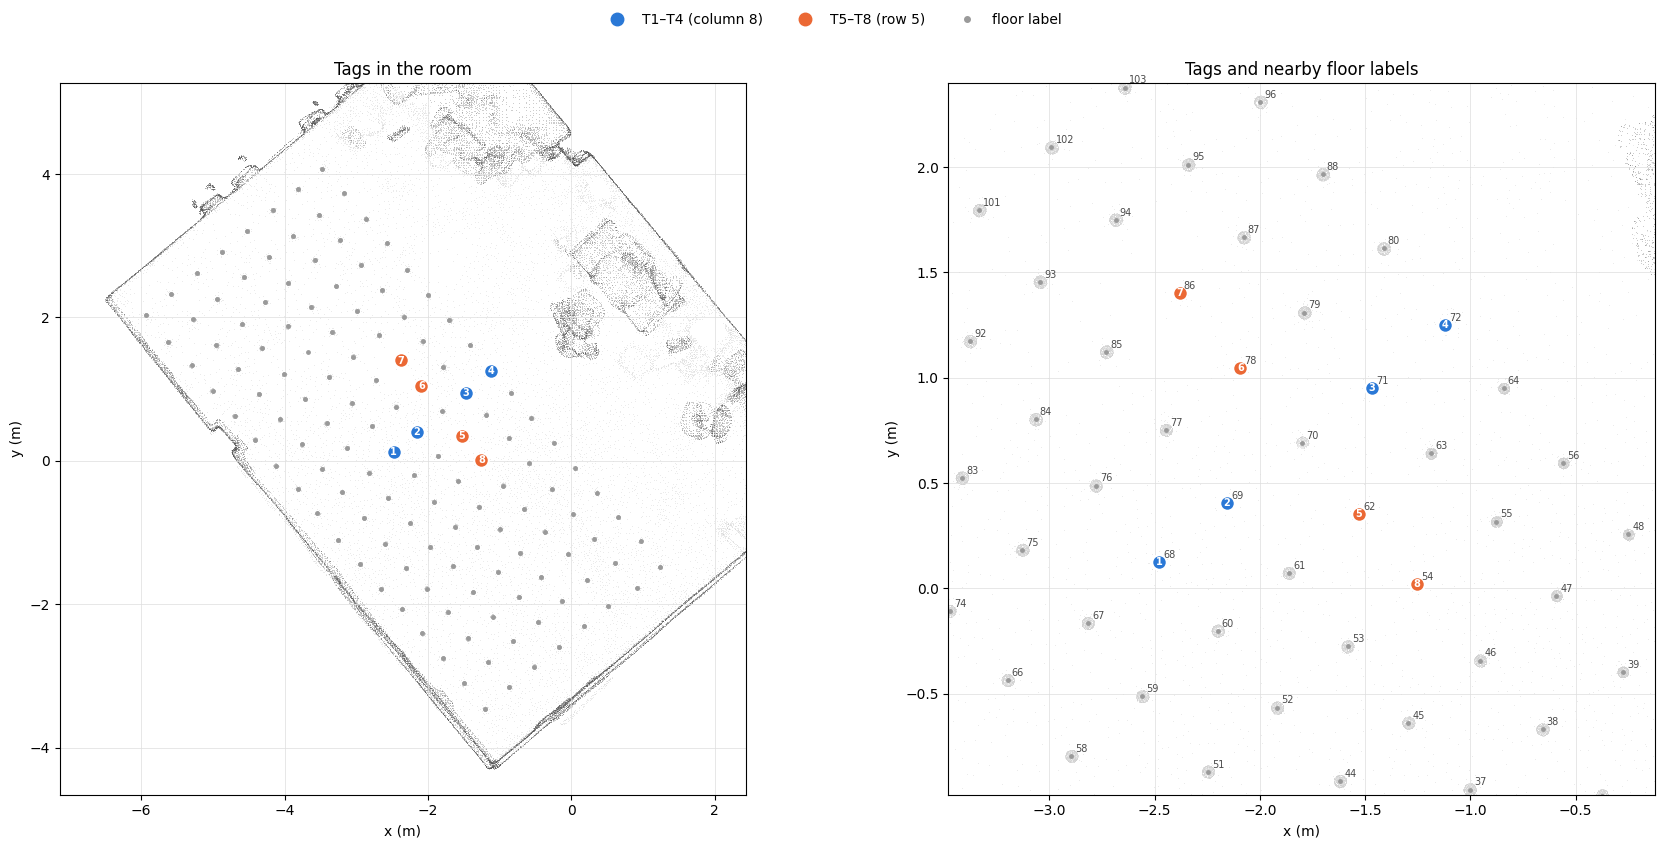

In [5]:
def tag_color(tag):
    for color, tags in zip(GROUP_COLORS, TAG_GROUPS.values()):
        if int(tag) in tags:
            return color
    return "#333333"


def draw_tags(ax, pos, size=110, fontsize=7):
    for tag, r in pos.iterrows():
        color = tag_color(tag)
        ax.scatter(r.x, r.y, s=size, color=color, edgecolors="white", linewidths=1.5, zorder=3)
        ax.annotate(tag, (r.x, r.y), ha="center", va="center", fontsize=fontsize, color="white",
                    fontweight="bold", zorder=4)


fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
for ax, zoom in zip(axes, (False, True)):
    draw_room(ax)
    draw_tags(ax, ref)
    if zoom:
        pad = 1.0
        x0, x1 = ref["x"].min() - pad, ref["x"].max() + pad
        y0, y1 = ref["y"].min() - pad, ref["y"].max() + pad
        near = markers[markers["x"].between(x0, x1) & markers["y"].between(y0, y1)]
        for lab, r in near.iterrows():
            ax.annotate(str(lab), (r.x, r.y), xytext=(3, 3), textcoords="offset points", fontsize=7,
                        color="#4a4a4a")
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
        ax.set_title("Tags and nearby floor labels")
    else:
        pad = 1.2
        ax.set_xlim(markers["x"].min() - pad, markers["x"].max() + pad)
        ax.set_ylim(markers["y"].min() - pad, markers["y"].max() + pad)
        ax.set_title("Tags in the room")
    ax.grid(True, color="#dddddd", lw=0.5)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=9, label=g)
           for g, c in zip(TAG_GROUPS, GROUP_COLORS)]
handles.append(plt.Line2D([], [], marker="o", ls="", color="#9a9a9a", markersize=4, label="floor label"))
fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## Bidirectional phase and attenuation: `[exp][T1][T2][freq]`

The same as the room sweep and metal-wall notebooks. For a pair `1 < 2` (by tag number), subscript `1` is the row
with **Rx = T1** (Tx = T2) and `2` the row with **Rx = T2** (Tx = T1), matched per run:

$$\hat\alpha_{12} = \frac{1}{2}\left(\frac{\hat\beta_1}{\hat V_2} + \frac{\hat\beta_2}{\hat V_1}\right) \qquad
\hat\theta_{12} = \left(\frac{\hat\Theta_1 + \hat\Theta_2}{2}\right) \bmod \pi$$

- $\hat\Theta$ = `Unidirectional Phase (deg)` in radians → $\hat\theta_{12}$ (`theta_data`) in $[0, \pi)$
- $\hat\beta$ = `Unidirectional beta`, $\hat V$ = `Unidirectional V` → $\hat\alpha_{12}$ (`alpha_data`)

Each entry is the median over the runs at that frequency. θ̂ is an angle mod π, so its runs are first moved onto
the branch of their circular mean (`median_mod_pi`), which keeps runs on both sides of the 0 / π wrap together.

Only experiments with a CSV **and** positions are loaded. The `Channel_*_voltages` columns are skipped, since they
make the files large.

In [6]:
def load_csv(exp_dir, with_voltages=False):
    f = next(Path(exp_dir).glob("*.csv"))
    cols = pd.read_csv(f, nrows=0).columns
    usecols = cols if with_voltages else [c for c in cols if "voltages" not in c.lower()]
    return pd.read_csv(f, usecols=usecols)


def tag_num(name):
    return int(str(name).replace("Tag", ""))


def bidirectional(df):
    # Join each Rx=a/Tx=b row with its Rx=b/Tx=a counterpart (a < b) and compute THETA, alpha.
    keep = ["Rx", "Tx", "Frequency (MHz)", "Run Exp Num",
            "Unidirectional Phase (deg)", "Unidirectional V", "Unidirectional beta"]
    d = df[keep]
    fwd = d[d["Rx"].map(tag_num) < d["Tx"].map(tag_num)]    # Rx = a, Tx = b
    rev = d[d["Rx"].map(tag_num) > d["Tx"].map(tag_num)]    # Rx = b, Tx = a
    m = fwd.merge(rev, left_on=["Rx", "Tx", "Frequency (MHz)", "Run Exp Num"],
                  right_on=["Tx", "Rx", "Frequency (MHz)", "Run Exp Num"],
                  suffixes=("_a", "_b"), validate="one_to_one")
    th_a = np.deg2rad(m["Unidirectional Phase (deg)_a"])
    th_b = np.deg2rad(m["Unidirectional Phase (deg)_b"])
    m["THETA"] = ((th_a + th_b) / 2) % np.pi
    m["alpha"] = 0.5 * (m["Unidirectional beta_a"] / m["Unidirectional V_b"]
                        + m["Unidirectional beta_b"] / m["Unidirectional V_a"])
    return m.rename(columns={"Rx_a": "T1", "Tx_a": "T2"})


def median_mod_pi(x):
    # median of mod-π angles: move every run onto the branch of their circular mean first, so runs on both sides
    # of the 0 / π wrap are not split apart, then take the median and wrap it back into [0, π)
    x = np.asarray(x, float)
    c = (np.angle(np.mean(np.exp(2j * x))) / 2) % np.pi
    return float((c + np.median((x - c + np.pi / 2) % np.pi - np.pi / 2)) % np.pi)


def to_nested(m, col, reduce=np.median):
    # -> {T1: {T2: {freq: median over runs}}} with tags in numeric order
    out = {}
    m = m.sort_values(["T1", "T2", "Frequency (MHz)", "Run Exp Num"],
                      key=lambda s: s.map(tag_num) if s.name in ("T1", "T2") else s)
    for (t1, t2, f), g in m.groupby(["T1", "T2", "Frequency (MHz)"], sort=False):
        out.setdefault(t1, {}).setdefault(t2, {})[int(f)] = float(reduce(g[col].to_numpy()))
    return out


csv_exps = [d.name for d in exp_dirs if any(d.glob("*.csv")) and positions[d.name] is not None]
data = {name: load_csv(DATA_DIR / name) for name in csv_exps}
bidir = {name: bidirectional(df) for name, df in data.items()}
theta_data = {name: to_nested(m, "THETA", median_mod_pi) for name, m in bidir.items()}
alpha_data = {name: to_nested(m, "alpha") for name, m in bidir.items()}

for name, m in bidir.items():
    print(f"exp {name}: {len(m)} (pair, freq, run) rows, {m.groupby(['T1', 'T2']).ngroups} pairs, "
          f"{m['Frequency (MHz)'].nunique()} freqs, runs {sorted(m['Run Exp Num'].unique())}")

exp baseline: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs [np.int64(0), np.int64(1), np.int64(2)]
exp center: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs [np.int64(0), np.int64(1), np.int64(2)]
exp northeast: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs [np.int64(0), np.int64(1), np.int64(2)]
exp northwest: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs [np.int64(0), np.int64(1), np.int64(2)]
exp southeast: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs [np.int64(0), np.int64(1), np.int64(2)]
exp southwest: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs [np.int64(0), np.int64(1), np.int64(2)]
exp baseline2: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs [np.int64(0), np.int64(1), np.int64(2)]
exp baseline3_excitermoved: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs [np.int64(0), np.int64(1), np.int64(2)]
exp baseline4_excitermoved: 1932 (pair, freq, run) rows, 28 pairs, 23 freqs, runs [np.int64(0), np.int64(1), np.int64(2

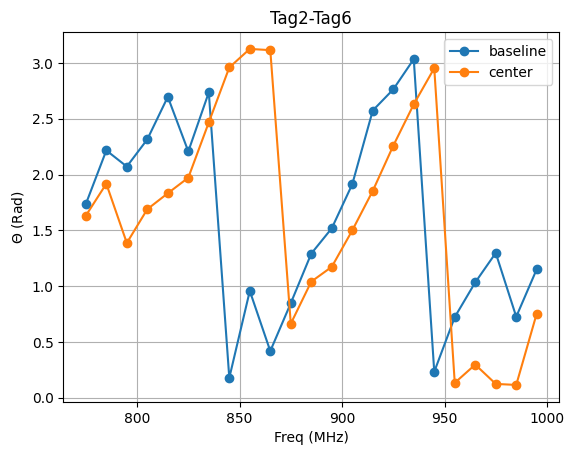

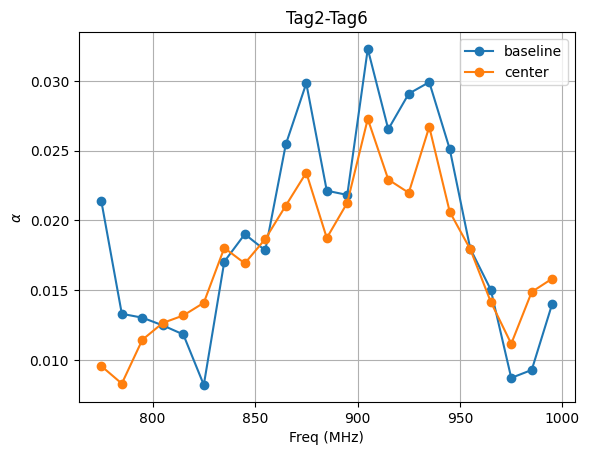

In [7]:
def plot_comparison(theta_data, alpha_data, tag_comb=["Tag2","Tag6"], experiments=['baseline','center']):
    experiments = experiments or [BASELINE, "baseline2"]
    # print(tag_comb[0]>tag_comb[1])
    # assert(tag_comb[0]>tag_comb[1], "illegal order")
        
    for exp in experiments:
        plt.plot(list(theta_data[exp][tag_comb[0]][tag_comb[1]].keys()), list(theta_data[exp][tag_comb[0]][tag_comb[1]].values()), 'o-', label=exp)
    plt.legend()
    plt.grid()
    plt.xlabel("Freq (MHz)")
    plt.ylabel("$\Theta$ (Rad)")
    plt.title(f"{tag_comb[0]}-{tag_comb[1]}")
    plt.show()
    
    for exp in experiments:
            plt.plot(list(alpha_data[exp][tag_comb[0]][tag_comb[1]].keys()), list(alpha_data[exp][tag_comb[0]][tag_comb[1]].values()), 'o-', label=exp)
    plt.legend()
    plt.grid()
    plt.xlabel("Freq (MHz)")
    plt.ylabel("$\\alpha$")
    plt.title(f"{tag_comb[0]}-{tag_comb[1]}")
    plt.show()

plot_comparison(theta_data, alpha_data)

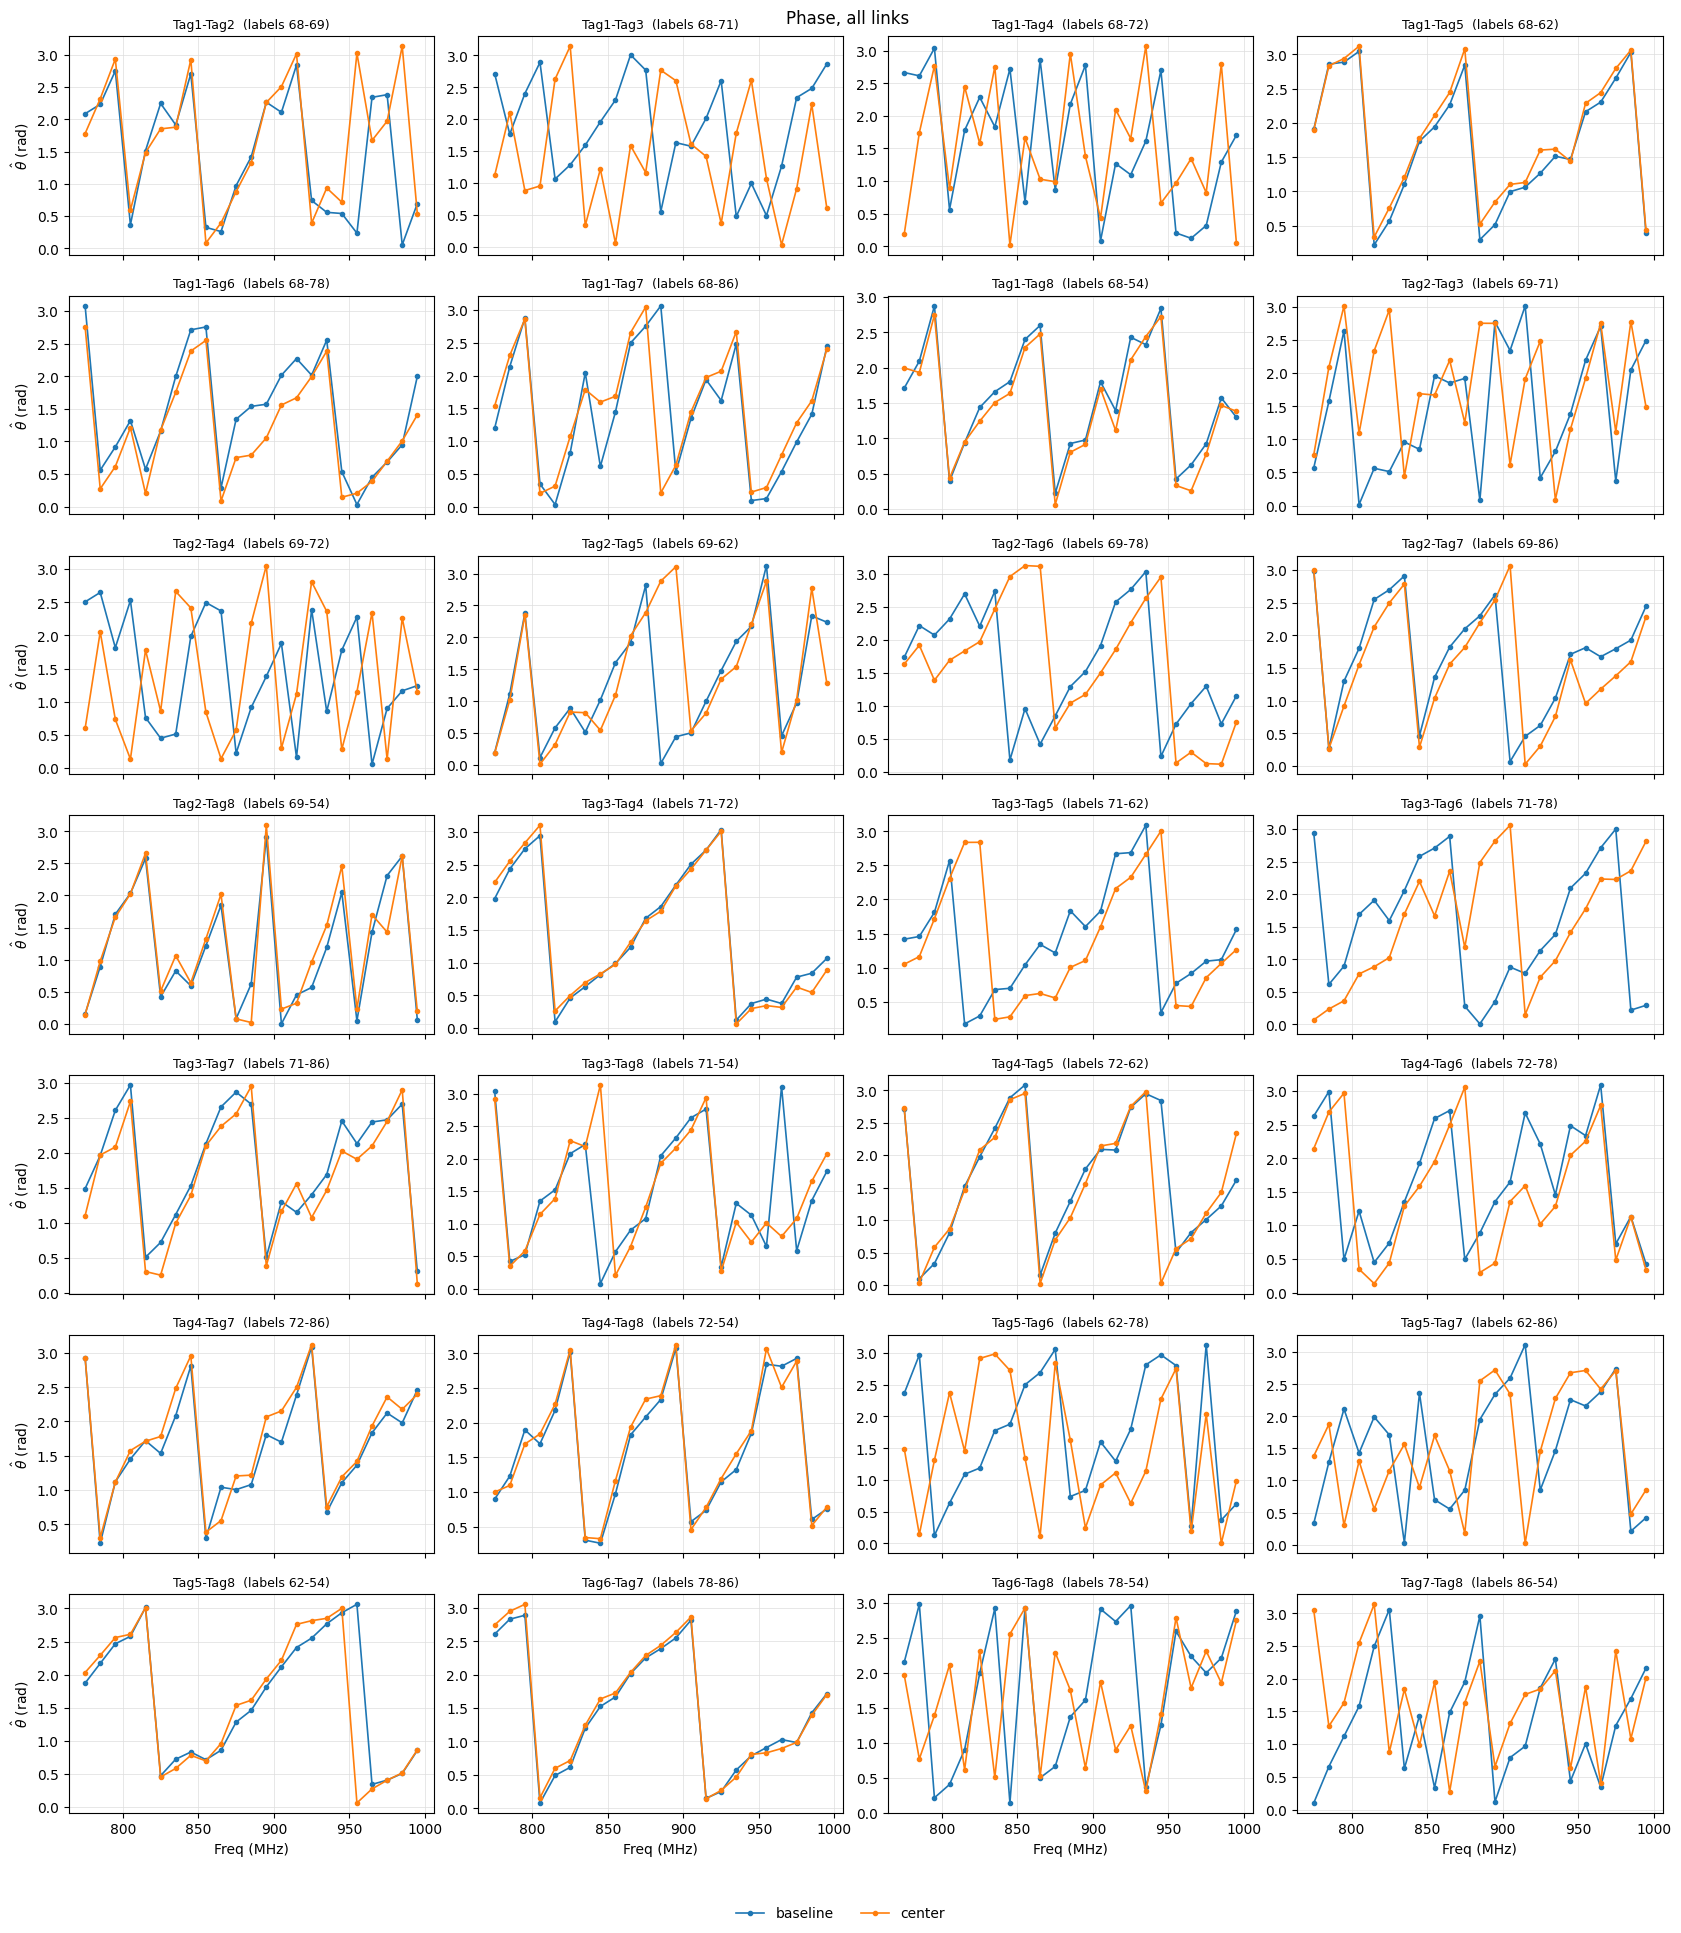

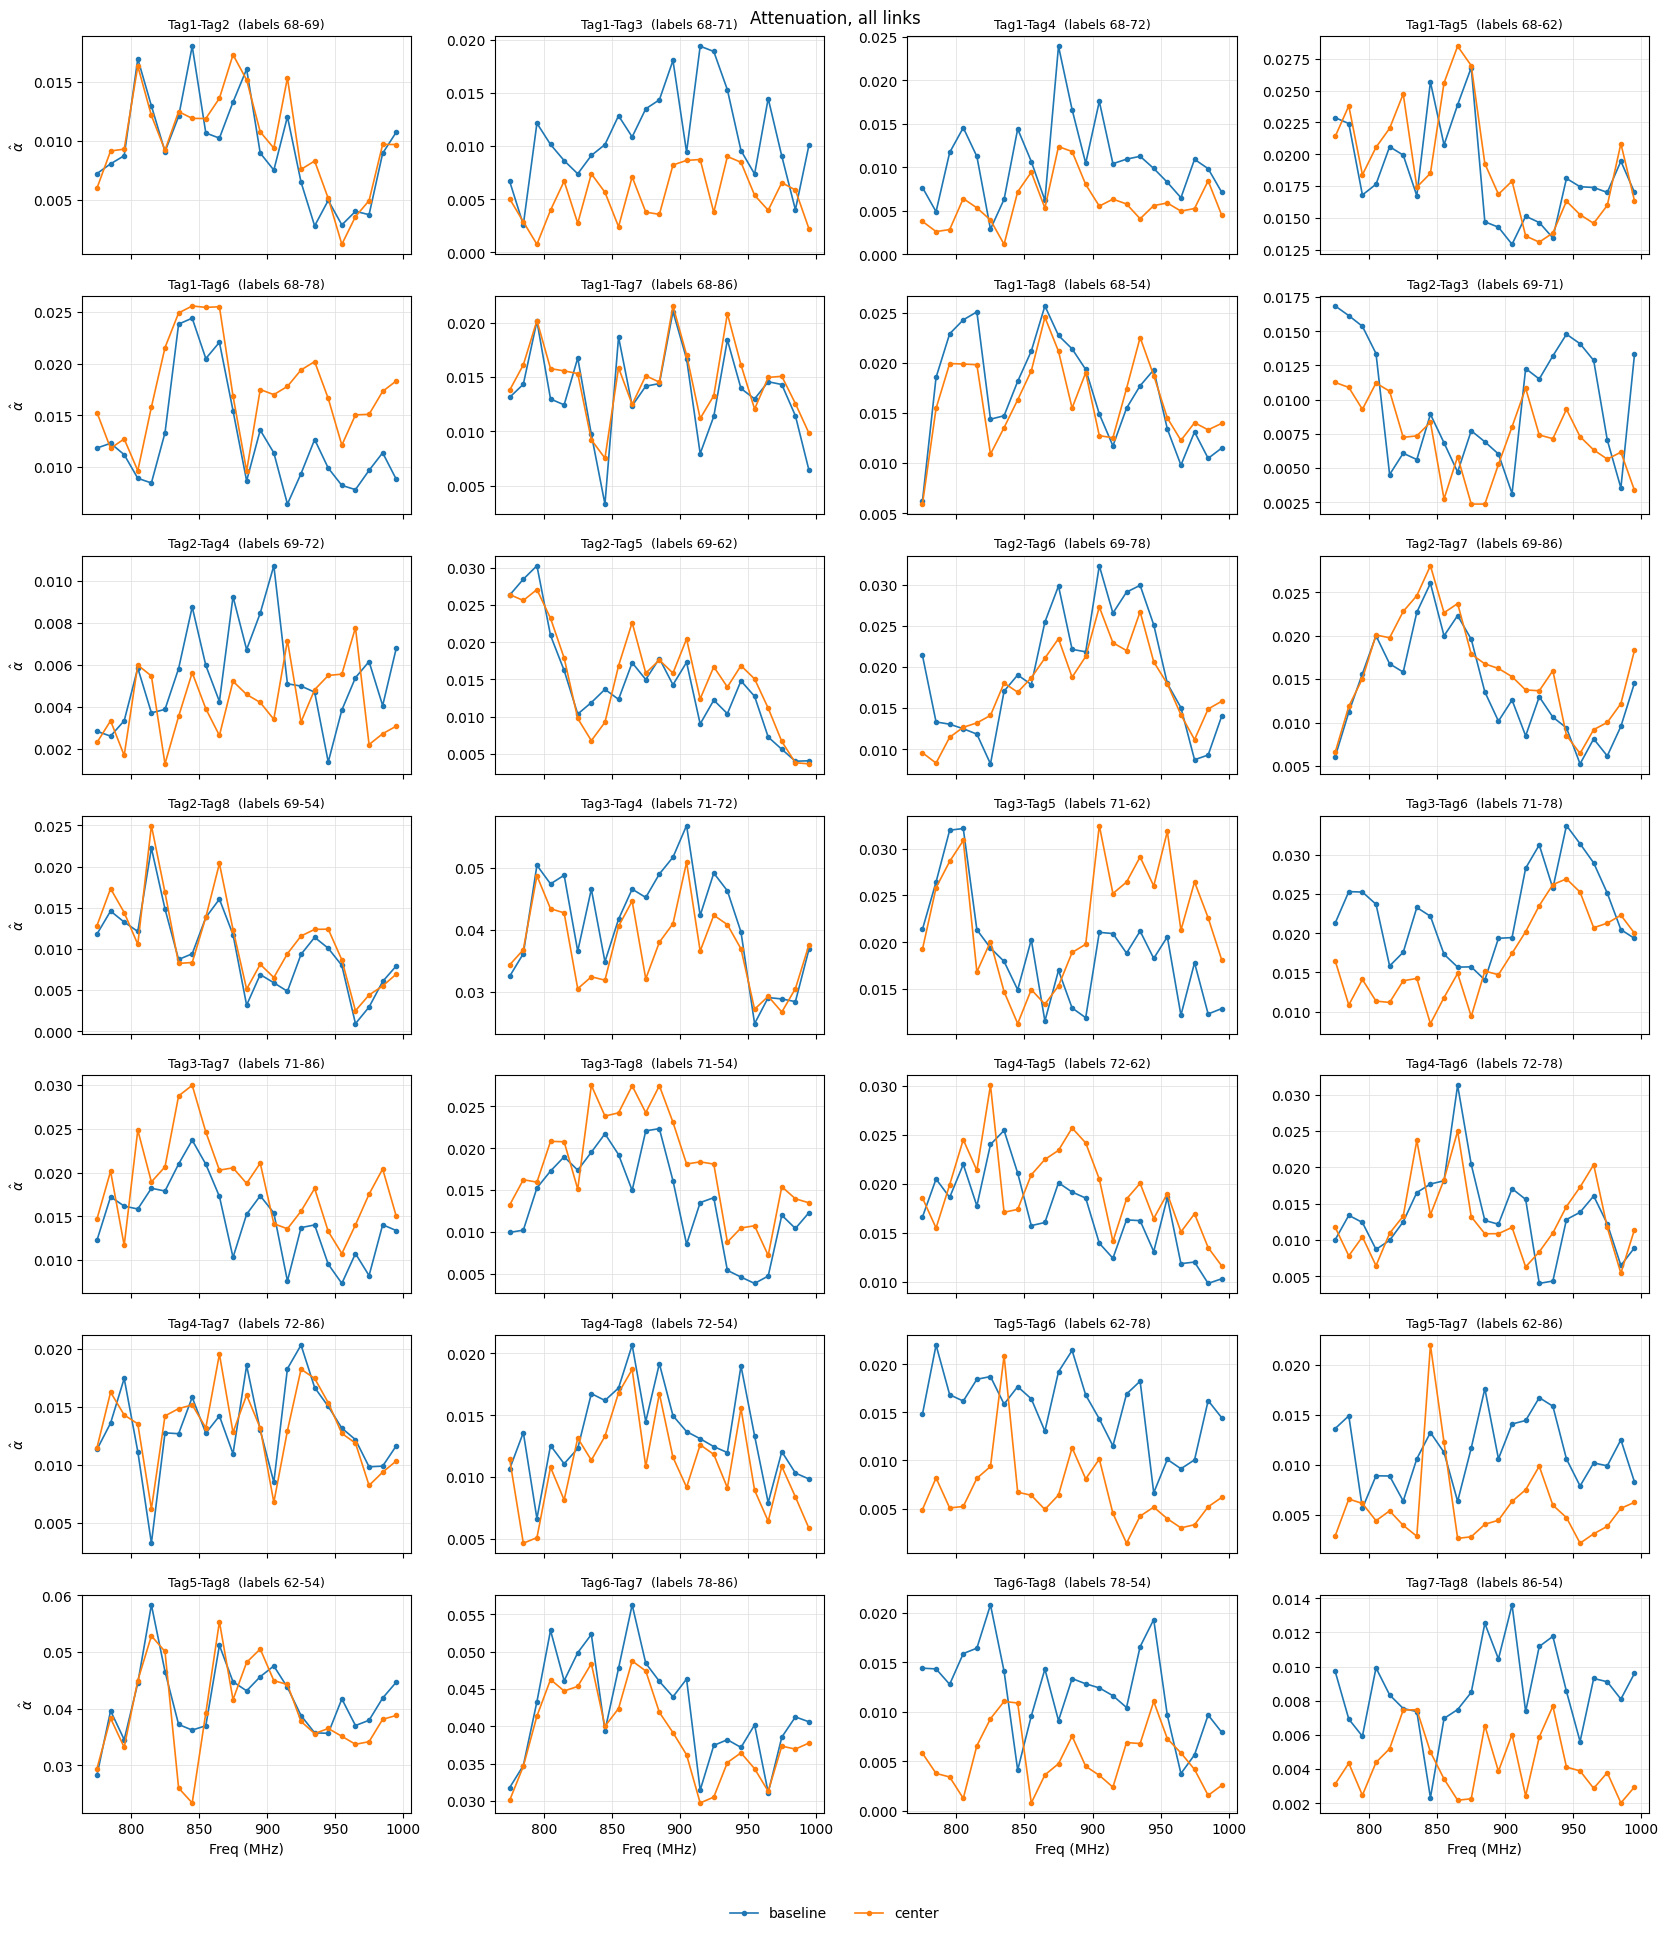

In [8]:
def plot_comparison_all(theta_data, alpha_data, experiments=None, n_cols=4):
    experiments = experiments or [BASELINE, "center"]
    # like plot_comparison, but for every link: one figure for θ̂ and one for α̂, each with a subplot per tag pair
    pairs = [(t1, t2) for t1 in theta_data[experiments[0]] for t2 in theta_data[experiments[0]][t1]]
    n_rows = int(np.ceil(len(pairs) / n_cols))
    for data, ylabel, name in [(theta_data, r"$\hat\theta$ (rad)", "Phase"),
                               (alpha_data, r"$\hat\alpha$", "Attenuation")]:
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 2.8 * n_rows), sharex=True, squeeze=False)
        for ax, (t1, t2) in zip(axes.flat, pairs):
            for exp in experiments:
                curve = data[exp][t1][t2]
                ax.plot(list(curve.keys()), list(curve.values()), "o-", ms=3, lw=1.2, label=exp)
            l1, l2 = ref.loc[str(tag_num(t1)), "label"], ref.loc[str(tag_num(t2)), "label"]
            ax.set_title(f"{t1}-{t2}  (labels {l1}-{l2})", fontsize=9)
            ax.grid(True, color="#dddddd", lw=0.5)
        for ax in axes.flat[len(pairs):]:
            ax.axis("off")
        for ax in axes[:, 0]:
            ax.set_ylabel(ylabel)
        for ax in axes[-1]:
            ax.set_xlabel("Freq (MHz)")
            ax.xaxis.set_tick_params(labelbottom=True)
        handles, labels = axes.flat[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="lower center", ncol=len(experiments), frameon=False)
        fig.suptitle(f"{name}, all links", fontsize=12)
        fig.tight_layout(rect=(0, 0.03, 1, 1))
        plt.show()


plot_comparison_all(theta_data, alpha_data)


### Distance from the baseline, every link

The baseline is the experiment named by `BASELINE` (first cell). Each link becomes one vector: its θ̂ at every frequency followed by its α̂ at every frequency. For each experiment,
the Euclidean distance between that vector and the same link's baseline vector says how much the person changed the
link.

- **Scaling.** θ̂ is in radians (0 to π) and α̂ is around 0.01. Unscaled, θ̂ would make up the whole distance, so each
  half is divided by its spread (standard deviation) in the baseline over all links and frequencies. Both halves
  then count about equally.
- **Phase wrap.** θ̂ is an angle mod π, so a θ̂ difference is taken the short way round, at most π/2. For example
  3.1 and 0.05 are 0.09 apart, not 3.05.

The heatmap has one row per link and one column per experiment. Darker cells are links the person changed more.

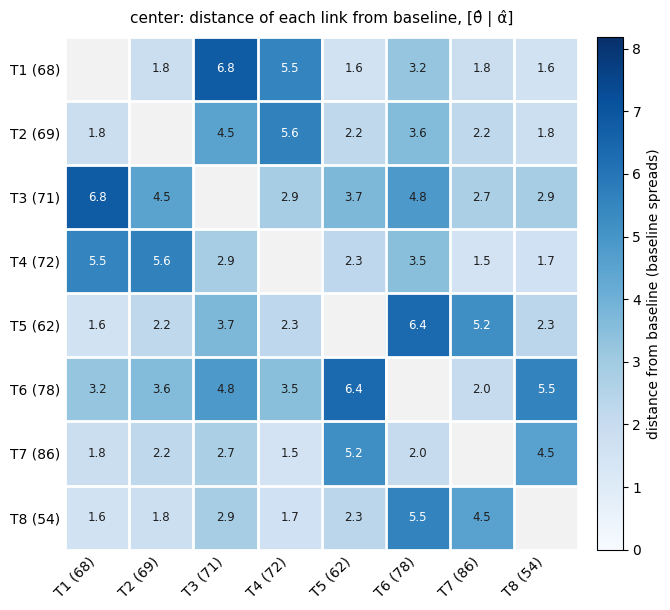

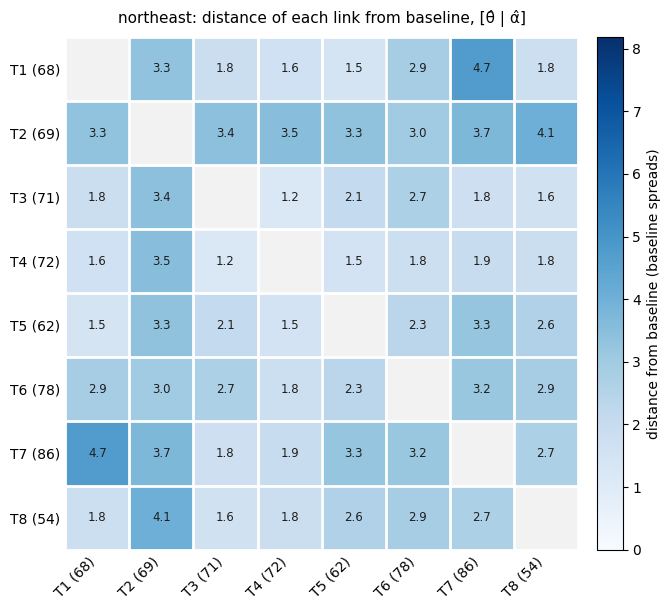

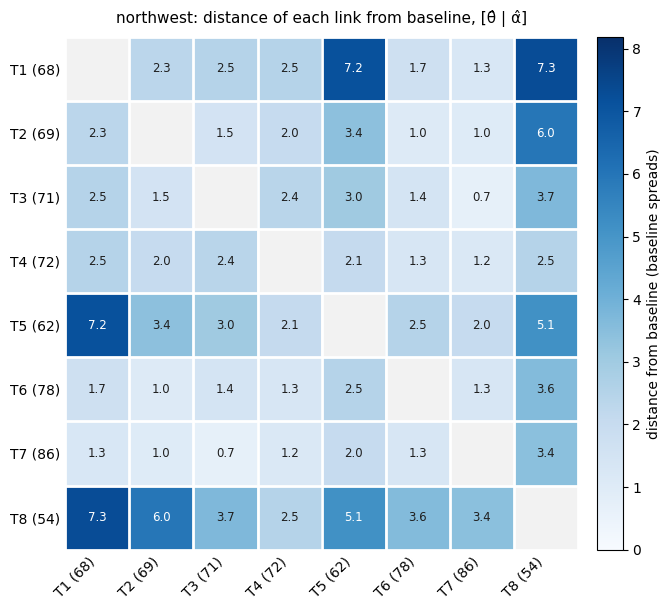

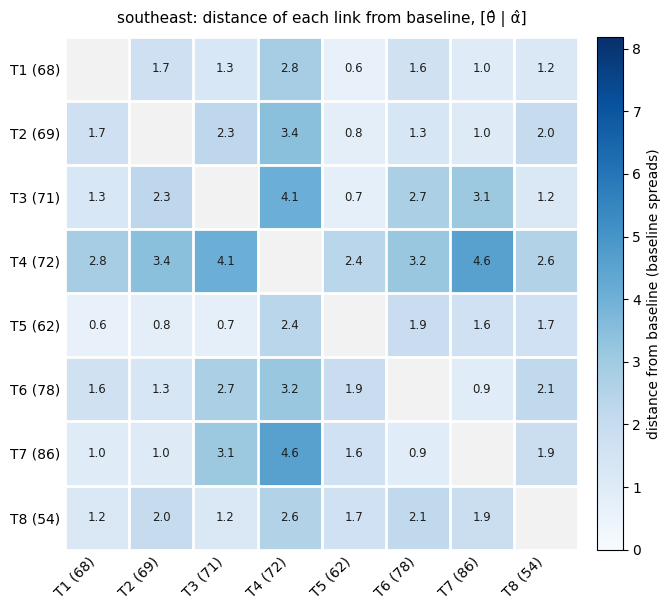

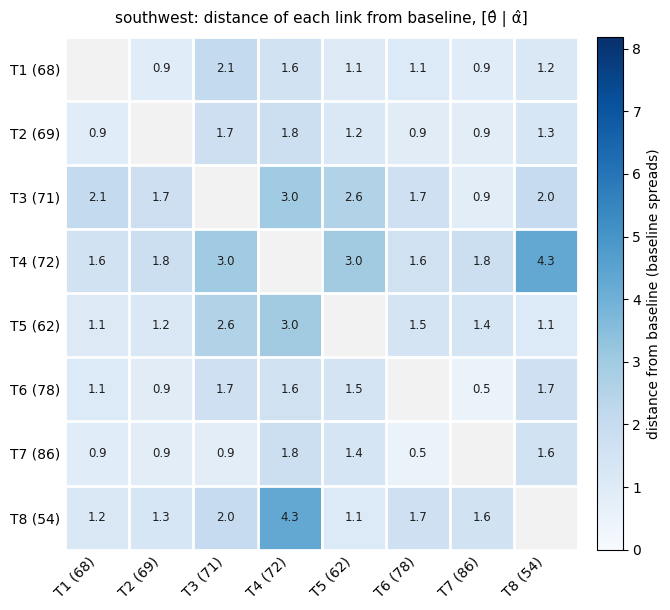

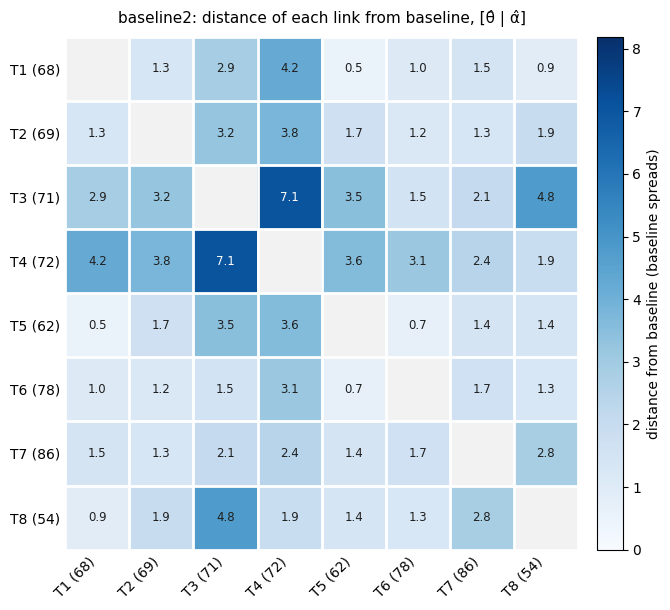

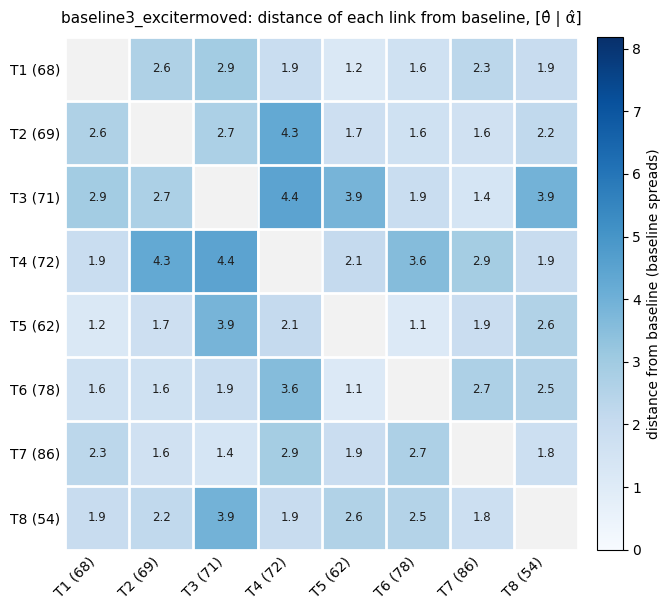

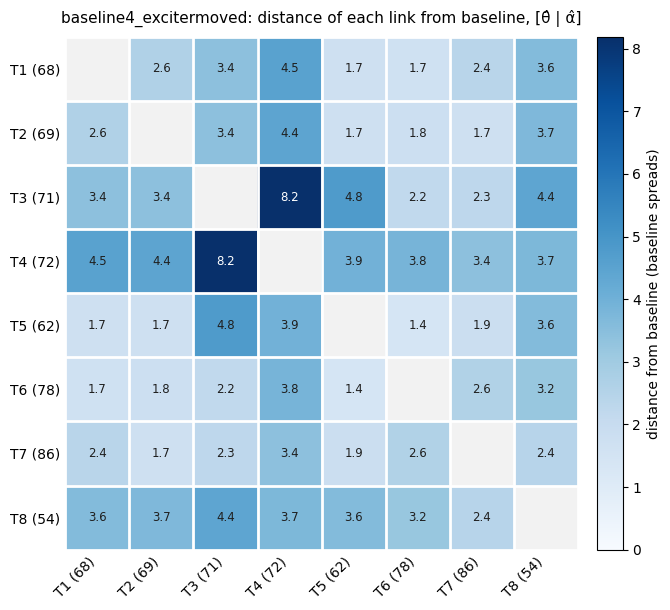

In [9]:
def link_vector(exp, t1, t2):
    # θ̂ over all frequencies, then α̂ over all frequencies (the frequency order of the baseline)
    freqs = list(theta_data[BASELINE][t1][t2])
    return (np.array([theta_data[exp][t1][t2][f] for f in freqs]),
            np.array([alpha_data[exp][t1][t2][f] for f in freqs]))


def distance_matrix(exp, baseline=None, scale=True):
    # tag × tag DataFrame for one experiment: entry (a, b) is the distance between link a-b's [θ̂ | α̂] vector and its
    # baseline vector (symmetric, NaN on the diagonal). θ̂ and α̂ are each scaled by their baseline spread, and θ̂
    # differences are taken the short way round mod π.
    baseline = baseline or BASELINE
    pairs = [(t1, t2) for t1 in theta_data[baseline] for t2 in theta_data[baseline][t1]]
    tags = sorted({t for p in pairs for t in p}, key=tag_num)
    base = {p: link_vector(baseline, *p) for p in pairs}
    s_theta = np.std(np.concatenate([b[0] for b in base.values()])) if scale else 1.0
    s_alpha = np.std(np.concatenate([b[1] for b in base.values()])) if scale else 1.0
    M = pd.DataFrame(np.nan, index=tags, columns=tags)
    for t1, t2 in pairs:
        (th0, al0), (th, al) = base[(t1, t2)], link_vector(exp, t1, t2)
        d_theta = (th - th0 + np.pi / 2) % np.pi - np.pi / 2      # shortest way round mod π
        M.loc[t1, t2] = M.loc[t2, t1] = np.linalg.norm(np.concatenate([d_theta / s_theta, (al - al0) / s_alpha]))
    return M


def plot_distance_matrix(M, exp, vmax=None):
    # one experiment's tag × tag distance matrix, like a confusion matrix
    names = [f"T{tag_num(t)} ({ref.loc[str(tag_num(t)), 'label']})" for t in M.index]
    vals = M.to_numpy()
    vmax = vmax or np.nanmax(vals)
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("#f2f2f2")                                        # diagonal: no link
    im = ax.imshow(np.ma.masked_invalid(vals), cmap=cmap, vmin=0, vmax=vmax)
    for i in range(len(M)):
        for j in range(len(M)):
            if np.isfinite(vals[i, j]):
                ax.text(j, i, f"{vals[i, j]:.1f}", ha="center", va="center", fontsize=8.5,
                        color="white" if vals[i, j] > 0.6 * vmax else "#1f1f1f")
    ax.set_xticks(range(len(M)), names, rotation=45, ha="right")
    ax.set_yticks(range(len(M)), names)
    ax.set_xticks(np.arange(len(M) + 1) - 0.5, minor=True)
    ax.set_yticks(np.arange(len(M) + 1) - 0.5, minor=True)
    ax.grid(which="minor", color="white", lw=2)
    ax.tick_params(which="both", length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label=f"distance from {BASELINE} ({BASELINE} spreads)")
    ax.set_title(f"{exp}: distance of each link from {BASELINE}, [θ̂ | α̂]", fontsize=11, pad=10)
    fig.tight_layout()
    plt.show()


experiments = [e for e in theta_data if e != BASELINE]
matrices = {exp: distance_matrix(exp) for exp in experiments}
VMAX = max(np.nanmax(M.to_numpy()) for M in matrices.values())    # one colour scale for all experiments
for exp, M in matrices.items():
    plot_distance_matrix(M, exp, vmax=VMAX)


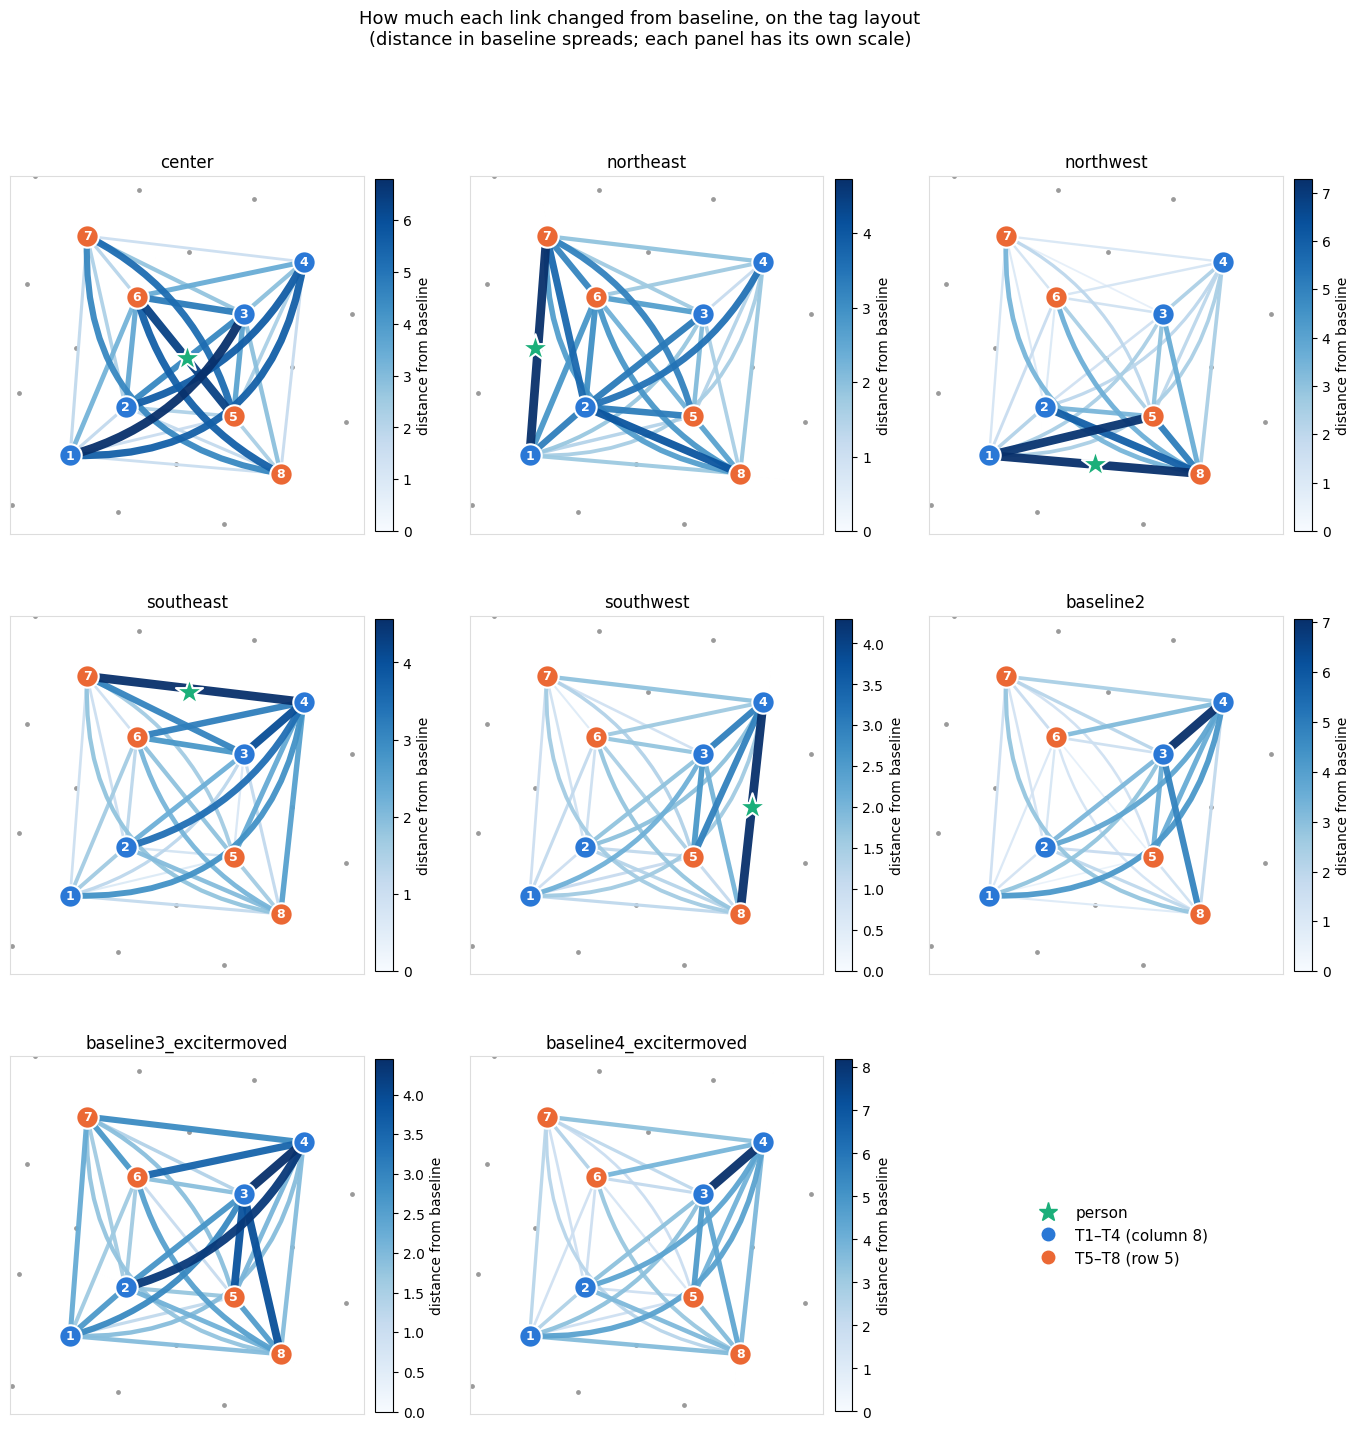

In [10]:
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch


# where the person stood, as the floor label in the middle of each quadrant of the tag cross (from the layout sketch;
# edit if the real spots differ). The cross is column 8 (T1-T4) and row 5 (T8, T5, T6, T7) around label 70.
PERSON_LABEL = {"center": 70, "northeast": 77, "southeast": 79, "southwest": 63, "northwest": 61}


def link_curvature(t1, t2):
    # links between tags on the same arm overlap the shorter ones, so bend them by how many tags they skip
    xy = {t: ref.loc[str(tag_num(t)), ["x", "y"]].to_numpy(float) for t in (t1, t2)}
    a, b = xy[t1], xy[t2]
    skipped = 0
    for tag, r in ref.iterrows():
        p = r[["x", "y"]].to_numpy(float)
        if tag in (str(tag_num(t1)), str(tag_num(t2))):
            continue
        u = np.clip((p - a) @ (b - a) / ((b - a) @ (b - a)), 0, 1)
        if 0 < u < 1 and np.linalg.norm(a + u * (b - a) - p) < 0.08:   # another tag lies on the segment
            skipped += 1
    return 0.0 if skipped == 0 else 0.22 * skipped


def plot_layout_distance(matrices, experiments=None, vmax=None, n_cols=3):
    # one panel per experiment: tags at their floor positions, each link drawn between its tags, coloured and
    # thickened by its distance from the baseline; the star is where the person stood. Every panel has its own
    # colour bar, scaled to that experiment's largest distance (pass vmax to use one fixed scale instead)
    experiments = experiments or list(matrices)
    cmap = plt.get_cmap("Blues")
    n_rows = int(np.ceil(len(experiments) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.6 * n_cols, 5.4 * n_rows), squeeze=False)
    pad = 0.35
    x0, x1 = ref["x"].min() - pad, ref["x"].max() + pad
    y0, y1 = ref["y"].min() - pad, ref["y"].max() + pad
    for ax, exp in zip(axes.flat, experiments):
        M = matrices[exp]
        norm = Normalize(0, vmax or np.nanmax(M.to_numpy()))
        links = sorted(((M.loc[a, b], a, b) for i, a in enumerate(M.index) for b in M.index[i + 1:]))
        for d, a, b in links:                                     # weakest first, so the strongest are on top
            pa = ref.loc[str(tag_num(a)), ["x", "y"]].to_numpy(float)
            pb = ref.loc[str(tag_num(b)), ["x", "y"]].to_numpy(float)
            ax.add_patch(FancyArrowPatch(pa, pb, arrowstyle="-", connectionstyle=f"arc3,rad={link_curvature(a, b)}",
                                         color=cmap(norm(d)), lw=0.8 + 5.5 * norm(d), alpha=0.95, zorder=2,
                                         capstyle="round"))
        ax.scatter(markers["x"], markers["y"], s=6, c="#9a9a9a", zorder=1)
        draw_tags(ax, ref, size=260, fontsize=9)
        if exp in PERSON_LABEL:
            px, py = markers.loc[PERSON_LABEL[exp], ["x", "y"]]
            ax.scatter(px, py, marker="*", s=420, color="#1baf7a", edgecolors="white", linewidths=1.5, zorder=5)
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        for side in ax.spines.values():
            side.set_color("#dddddd")
        ax.set_title(exp, fontsize=12)
        fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.046, pad=0.03,
                     label=f"distance from {BASELINE}")
    for ax in axes.flat[len(experiments):]:
        ax.axis("off")
    handles = [plt.Line2D([], [], marker="*", ls="", color="#1baf7a", markersize=14, label="person")]
    handles += [plt.Line2D([], [], marker="o", ls="", color=c, markersize=9, label=g)
                for g, c in zip(TAG_GROUPS, GROUP_COLORS)]
    fig.legend(handles=handles, loc="center", bbox_to_anchor=axes.flat[-1].get_position(), frameon=False, fontsize=11)
    fig.suptitle(f"How much each link changed from {BASELINE}, on the tag layout\n"
                 f"(distance in {BASELINE} spreads; each panel has its own scale)", fontsize=13)
    plt.show()


matrices = {exp: distance_matrix(exp) for exp in theta_data if exp != BASELINE}
plot_layout_distance(matrices)
